# 7.5 Experimental Design

**Goal:** design experiments with randomization, blocking, factorial structure, and prospective power.

**Prerequisites:** Modules 0–4 and earlier notebooks in this module; advanced notebooks also build on earlier modules 5–8. Read the section assumptions before using a method.

**Runtime:** Python 3.10+ with NumPy, SciPy, and Matplotlib. Install in your chosen environment with `python3 -m pip install numpy scipy matplotlib`, then open in JupyterLab or VS Code with a Python kernel. Use **Restart Kernel and Run All**. Each notebook is self-contained, includes saved outputs, uses synthetic data and a fixed local random seed, and needs no downloads. Numerical simulations illustrate results; they do not prove them or validate real-world assumptions.

## Module navigation

1. [Bayesian Statistics](1_Bayesian-Statistics.ipynb)
2. [Parameter Estimation](2_Parameter-Estimation.ipynb)
3. [Multivariate Statistics](3_Multivariate-Statistics.ipynb)
4. [Resampling Methods](4_Resampling-Methods.ipynb)
5. [Experimental Design](5_Experimental-Design.ipynb)

## Learning route

Read each definition and assumption, work through its calculation, run the code, then attempt the practice before viewing the solutions. Distinguish descriptive association, causal inference, and predictive evaluation throughout.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize, special, linalg
rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 12, "font.size": 10})

## 1. Randomized Controlled Experiments; Control Groups and Treatment Groups

A controlled experiment compares assigned conditions; randomization makes treatment assignment independent of potential outcomes under the design and supports causal inference with suitable compliance, interference, and observation assumptions. A control can be existing practice or another relevant treatment, not necessarily no treatment.

Specify eligibility, assignment unit, outcome window, estimand, primary metric, exclusion rules, and stopping plan before observing favorable results. Intention-to-treat analyzes by assigned condition; per-protocol comparisons can reintroduce selection bias. Random assignment does not make volunteers representative of every deployment population.

In [2]:
ids=np.arange(80);assignment=rng.permutation(ids)
control,treatment=assignment[:40],assignment[40:]
print("Assigned control/treatment counts:",len(control),len(treatment))
assert not set(control)&set(treatment)

Assigned control/treatment counts: 40 40


## 2. Randomization and Blocking

**Blocking** groups similar experimental units using pre-treatment factors, then randomizes within blocks. It can improve precision and enforce balanced comparisons across sites or baseline-risk groups. Analysis should respect the block design. Post-treatment blocking or excluding units based on observed outcomes can change the estimand and introduce bias.

Cluster randomization assigns whole groups to limit interference or administrative contamination; uncertainty then depends on clusters. An 80-user trial assigned by two teams does not create 80 independent treatment assignments. Blocking and clustering solve different design issues.

In [3]:
block=np.repeat(["site A","site B"],40)
labels=np.empty(80,dtype=int)
for site in np.unique(block):
    idx=np.flatnonzero(block==site);idx=rng.permutation(idx)
    labels[idx[:20]]=0;labels[idx[20:]]=1
print("Treatment counts by site:",{s:int(labels[block==s].sum()) for s in np.unique(block)})

Treatment counts by site: {np.str_('site A'): 20, np.str_('site B'): 20}


## 3. Factorial Design

A factorial design crosses factor levels so main effects and interactions can be studied efficiently. A 2×2 experiment has four cells. An interaction contrast is $(\mu_{11}-\mu_{10})-(\mu_{01}-\mu_{00})$: the difference in one factor's effect across the other. Average main effects can conceal opposing subgroup effects, so inspect prespecified interactions.

Replication estimates residual variation; repeated readings on the same assigned unit are not independent treatment replications. Fractional factorial designs can reduce cost but alias effects under assumptions; they are not interchangeable with observing every combination.

2x2 interaction contrast: 4.0


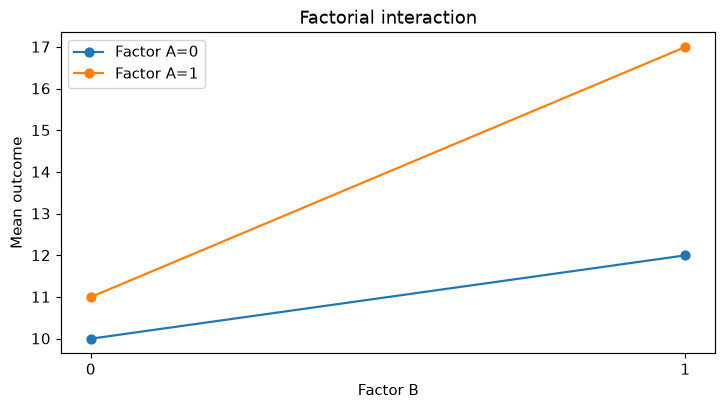

In [4]:
means=np.array([[10.,12.],[11.,17.]])
interaction=(means[1,1]-means[1,0])-(means[0,1]-means[0,0])
print("2x2 interaction contrast:",interaction)
fig,ax=plt.subplots()
for a in range(2):ax.plot([0,1],means[a],marker="o",label=f"Factor A={a}")
ax.set(title="Factorial interaction",xlabel="Factor B",ylabel="Mean outcome",xticks=[0,1]);ax.legend()
fig.tight_layout();plt.show()

## 4. A/B Testing and Statistical Power Analysis

An A/B test is an experiment, not just a before/after comparison. Persistent user-level assignment, common measurement rules, a stable outcome window, and a valid stopping rule matter. Guardrail metrics can reveal harms despite improvement in a primary metric. Multiple variants, metrics, and repeated looks require an error-control plan.

For rough equal-allocation two-proportion planning, using a common approximate p gives $n_{per\ arm}\approx2p(1-p)(z_{1-α/2}+z_{power})²/\Delta²$. This is a normal approximation for planning, not an exact small-sample guarantee; use design-specific calculations for final sizing and account for attrition/clustering. Plan for a relevant minimum effect rather than the optimistic effect from a noisy pilot.

**Example:** baseline p=.2, desired absolute improvement .03, α=.05 and power .8 produce a rough sample count per arm. A 3 percentage-point gain is not a 3% relative gain: relative gain is .03/.2=15%.

In [5]:
p=.2;delta=.03;alpha=.05;power=.8
n_arm=math.ceil(2*p*(1-p)*(stats.norm.ppf(1-alpha/2)+stats.norm.ppf(power))**2/delta**2)
print("Approximate independent users per arm:",n_arm,"relative lift:",delta/p)

Approximate independent users per arm: 2791 relative lift: 0.15


## AI/ML application and interpretation

Experimental design supports causal product evaluation and algorithm comparisons. Model benchmarks on reused datasets are not automatically randomized deployment experiments. Document target population, assignment, attrition, exposure, metric multiplicity, and practical decision thresholds; retain reliable logging and analysis of assigned units.

## Practice

1. Why can a before/after product metric fail to identify an intervention effect?
2. Distinguish blocking from cluster assignment.
3. Does an interaction contrast of zero prove each treatment has no effect?
4. Why plan a stopping rule before running an A/B test?

## Solutions

1. Seasonality, population changes, and concurrent events can explain the difference.
2. Blocking randomizes within every similarity group; clustering assigns entire groups as units.
3. No. It means no difference of the specified effects under that contrast; common main effects can remain.
4. Repeated unadjusted peeking and outcome-driven stopping can inflate false positives and bias estimates.

**Readiness check:** identify the estimand, independent unit, assumptions, uncertainty source, and an important failure mode before using these methods.

**Next:** [Continue studying](../8-Statistics-for-Machine-Learning/1_Data-Preprocessing.ipynb).